In [1]:
!pip install scqubits

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.2/82.2 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 2.4 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq


In [5]:
phi_grid=scq.Grid1d(min_val=-6*np.pi,max_val=6*np.pi,pt_count=101)

In [8]:
zero_pi=scq.ZeroPi(
    EJ=0.25,
    EL=0.01,
    ECJ=0.5,
    EC=None,
    ECS=0.001,
    ng=0.1,
    flux=0.23,
    dEJ=0.0,
    dCJ=0.0,
    grid=phi_grid,
    ncut=8,
    truncated_dim=6
)

In [10]:
evals,evecs=zero_pi.eigensys(evals_count=6)
print(evals)
print(evals-evals[0])

[0.45758514 0.4879014  0.49958903 0.51700325 0.52830058 0.54500518]
[0.         0.03031626 0.04200389 0.05941811 0.07071543 0.08742004]


In [11]:
f01=evals[1]-evals[0]
print(f"{f01:.6f} GHz")

0.030316 GHz


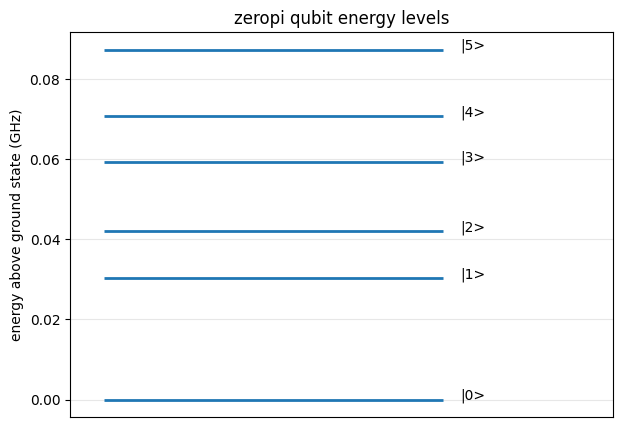

In [12]:
energies=evals-evals[0]
plt.figure(figsize=(7,5))
for i,energy in enumerate(energies):
  plt.hlines(energy,0,1,linewidth=2)
  plt.text(1.05,energy,f"|{i}>")

plt.xlim(-0.1,1.5)
plt.xticks([])
plt.ylabel("energy above ground state (GHz)")
plt.title("zeropi qubit energy levels")
plt.grid(axis="y",alpha=0.3)
plt.show()

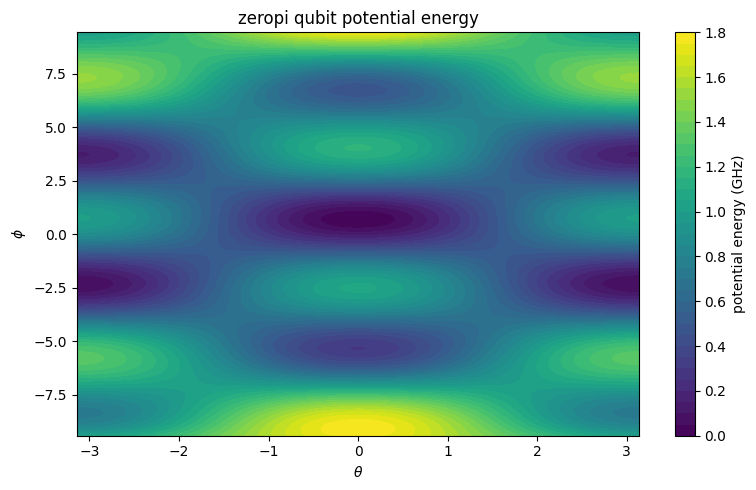

In [13]:
theta=np.linspace(-np.pi,np.pi,160)
phi=np.linspace(-3*np.pi,3*np.pi,200)
THETA,PHI=np.meshgrid(theta,phi)
U=(
    -2*zero_pi.EJ
    *np.cos(THETA)
    *np.cos(PHI-np.pi*zero_pi.flux)
    +zero_pi.EL*PHI**2+2*zero_pi.EJ
)
plt.figure(figsize=(8,5))
plt.contourf(THETA,PHI,U,levels=40)
plt.colorbar(label="potential energy (GHz)")
plt.xlabel(r"$\theta$")
plt.ylabel(r"$\phi$")
plt.title("zeropi qubit potential energy")
plt.tight_layout()
plt.show()

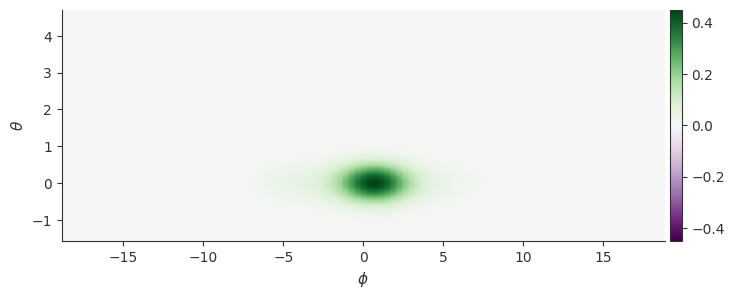

In [15]:
zero_pi.plot_wavefunction(
    esys=(evals,evecs)
,    which=0
)
plt.show()

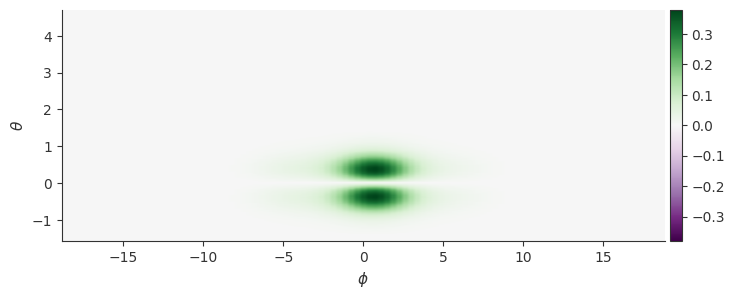

In [16]:
zero_pi.plot_wavefunction(
    esys=(evals,evecs),
    which=1
)
plt.show()

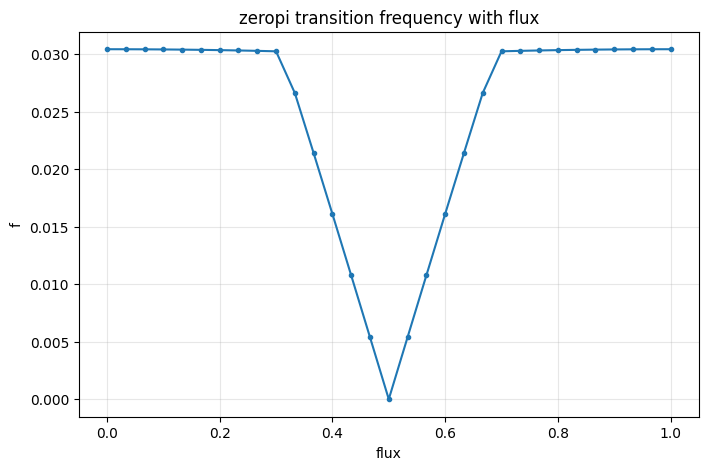

In [18]:
flux_values = np.linspace(0, 1, 31)
f01_values = []
for f in flux_values:
  zero_pi.set_params(flux=float(f))
  levels = zero_pi.eigenvals(evals_count=2)
  f01_values.append(levels[1] - levels[0])

zero_pi.set_params(flux=0.23)

plt.figure(figsize=(8, 5))
plt.plot(flux_values, f01_values, marker="o", markersize=3)
plt.xlabel("flux")
plt.ylabel("f")
plt.title("zeropi transition frequency with flux")
plt.grid(alpha=0.3)
plt.show()